# Train — DenseNet-121

Trains and evaluates DenseNet-121 with the tuned hyperparameters in `ARCH_HYPERPARAMS["densenet121"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: off
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["densenet121"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"DenseNet-121: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

DenseNet-121: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 947 | Val: 229 | Test: 567


## Model

In [3]:
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
in_f = model.classifier.in_features
model.classifier = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[DenseNet-121] Gradient accumulation: 2 micro-batches per optimizer step.


[DenseNet-121] Epoch   1/100 | LR: 1.39e-04 | train loss 0.8698 acc 0.648 | val loss 0.6799 acc 0.716 *


[DenseNet-121] Epoch   2/100 | LR: 1.39e-04 | train loss 0.5169 acc 0.811 | val loss 0.6112 acc 0.742 *


[DenseNet-121] Epoch   3/100 | LR: 1.39e-04 | train loss 0.3490 acc 0.894 | val loss 0.5964 acc 0.760 *


[DenseNet-121] Epoch   4/100 | LR: 1.39e-04 | train loss 0.1927 acc 0.951 | val loss 0.5809 acc 0.773 *


...

[DenseNet-121] Epoch  10/100 | LR: 1.39e-04 | train loss 0.0586 acc 0.982 | val loss 0.8907 acc 0.773


[DenseNet-121] Epoch  11/100 | LR: 1.39e-04 | train loss 0.1772 acc 0.943 | val loss 0.7883 acc 0.782


[DenseNet-121] Epoch  12/100 | LR: 1.39e-04 | train loss 0.1296 acc 0.959 | val loss 0.6484 acc 0.786


[DenseNet-121] Epoch  13/100 | LR: 1.39e-04 | train loss 0.0911 acc 0.978 | val loss 0.7125 acc 0.760


[DenseNet-121] Epoch  14/100 | LR: 1.39e-04 | train loss 0.0425 acc 0.992 | val loss 0.6831 acc 0.773

[DenseNet-121] No val loss improvement for 10 epochs, stopping at epoch 14.

[DenseNet-121] Restored best checkpoint (val loss = 0.5809)


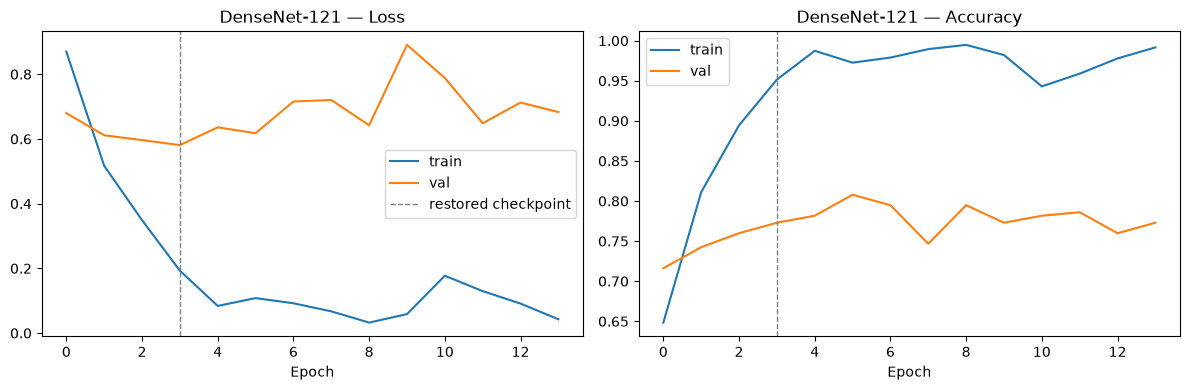

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "DenseNet-121", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "DenseNet-121")

## Evaluate on the test set

[DenseNet-121] Test accuracy: 0.852


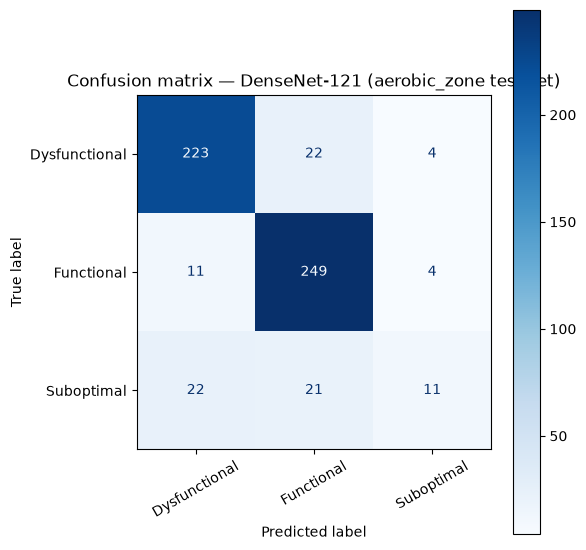

               precision    recall  f1-score   support

Dysfunctional      0.871     0.896     0.883       249
   Functional      0.853     0.943     0.896       264
   Suboptimal      0.579     0.204     0.301        54

     accuracy                          0.852       567
    macro avg      0.768     0.681     0.693       567
 weighted avg      0.835     0.852     0.834       567



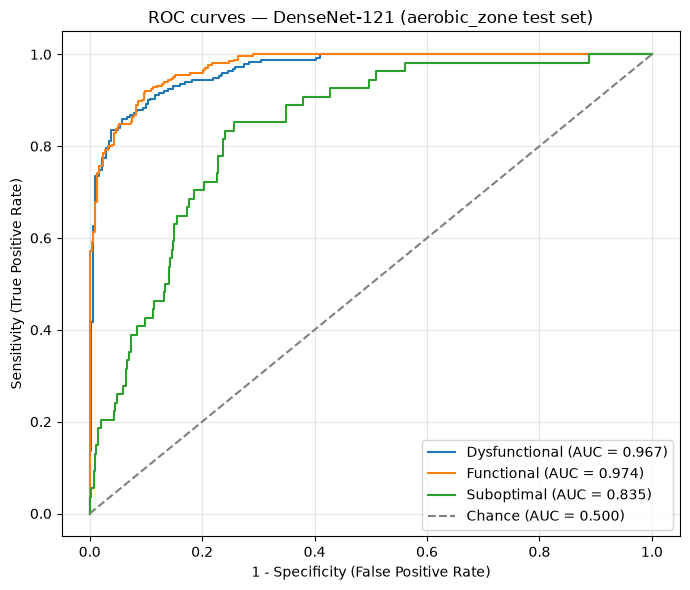

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.967
  Functional     : 0.974
  Suboptimal     : 0.835

Mean AUC (over 3/3 classes with test examples): 0.925


(np.float64(0.8518518518518519),
 {'Dysfunctional': 0.9666843474527038,
  'Functional': 0.9737348734873488,
  'Suboptimal': 0.8349577647823262})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "DenseNet-121", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("DenseNet-121", "densenet121")

Saved results to ../results/aerobic_zone_noaug/results_aerobic_zone_densenet121_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_noaug/aerobic_zone_densenet121_chronological.pt
